# MediCheck-GPT: run the full flow on Colab (v3)
Runtime → Change runtime type → **T4 GPU**. Run top to bottom.



## 0. Setup: GPU, code, data

In [31]:
!nvidia-smi --query-gpu=name,memory.total --format=csv   # confirm the T4 is attached

shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [32]:
from google.colab import drive
drive.mount('/content/drive')                     # the raw CMS file lives in my Drive
ROOT = '/content/drive/MyDrive/build-transformer'   # same folder as 01_data.ipynb

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [33]:
%cd /content
!rm -rf /content/medicheck-gpt                       # never run an old copy of the code (step out of it first)
!git clone https://github.com/cece15/medicheck-gpt.git /content/medicheck-gpt
%cd /content/medicheck-gpt
!pip install -q -r requirements.txt
# data and checkpoints live in Drive, so a Colab disconnect loses nothing: rerun from the cell that stopped
!mkdir -p "$ROOT/medicheck/data" "$ROOT/medicheck/checkpoints"
!ln -sfn "$ROOT/medicheck/data" data && ln -sfn "$ROOT/medicheck/checkpoints" checkpoints && ls -l
!git log --oneline -1                               # should NOT say 'Created using Colab'

/content
Cloning into '/content/medicheck-gpt'...
remote: Enumerating objects: 110, done.
remote: Counting objects: 100% (110/110), done.
remote: Compressing objects: 100% (74/74), done.
remote: Total 110 (delta 71), reused 62 (delta 30), pack-reused 0 (from 0)
Receiving objects: 100% (110/110), 186.10 KiB | 18.61 MiB/s, done.
Resolving deltas: 100% (71/71), done.
/content/medicheck-gpt
total 64
lrwxrwxrwx 1 root root    62 Nov 14 23:10 checkpoints -> /content/drive/MyDrive/build-transformer/medicheck/checkpoints
lrwxrwxrwx 1 root root    55 Nov 14 23:10 data -> /content/drive/MyDrive/build-transformer/medicheck/data
-rwxr-xr-x 1 root root 16247 Nov 14 23:10 gpt.py
drwxr-xr-x 2 root root  4096 Nov 14 23:10 notebooks
-rw-r--r-- 1 root root 15884 Nov 14 23:10 README.md
-rw-r--r-- 1 root root   140 Nov 14 23:10 requirements.txt
drwxr-xr-x 2 root root  4096 Nov 14 23:10 src
-rw-r--r-- 1 root root 12860 Nov 14 23:10 WALKTHROUGH.md
6345df9 (HEAD -> main, origin/main, origin/HEAD) Restore v3 

## 1. Data: CSV → one sentence per row → split by hospital

In [34]:
import os
if not os.path.exists('data/processed/test.txt'):
    !python gpt.py --input "$ROOT/data/raw/MUP_INP_RY26_P03_V10_DY24_PrvSvc.CSV" --prepare data/processed
!head -c 600 data/processed/train.txt


Corewell Health Zeeland Hospital in Zeeland, MI billed DRG 291 (HEART FAILURE AND SHOCK WITH MCC) for 20 discharges: covered charges $19134, total payment $9134, Medicare payment $7828.
Corewell Health Zeeland Hospital in Zeeland, MI billed DRG 871 (SEPTICEMIA OR SEVERE SEPSIS WITHOUT MV >96 HOURS WITH MCC) for 53 discharges: covered charges $28663, total payment $12681, Medicare payment $10761.
Corewell Health Zeeland Hospital in Zeeland, MI billed DRG 872 (SEPTICEMIA OR SEVERE SEPSIS WITHOUT MV >96 HOURS WITHOUT MCC) for 21 discharges: covered charges $19285, total payment $8101, Medicare p

## 2. Baseline: bigram (one character of memory)

In [35]:
if not os.path.exists('checkpoints/bigram.pth'):
    !python gpt.py --input data/processed --train checkpoints/bigram.pth --model bigram --context_size 8 --lr 1e-2 --steps 3000

## 3. Transformer: 4 layers, 4 heads, 128-dim, context 271 (one full record)
Cosine LR with warmup, weight decay, early stopping. First run (3 Nov) overfit after ~1,500 steps, so these guards matter.

In [36]:
if not os.path.exists('checkpoints/gpt.pth'):
    !python gpt.py --input data/processed --train checkpoints/gpt.pth --steps 10000 --eval_every 500 --patience 4

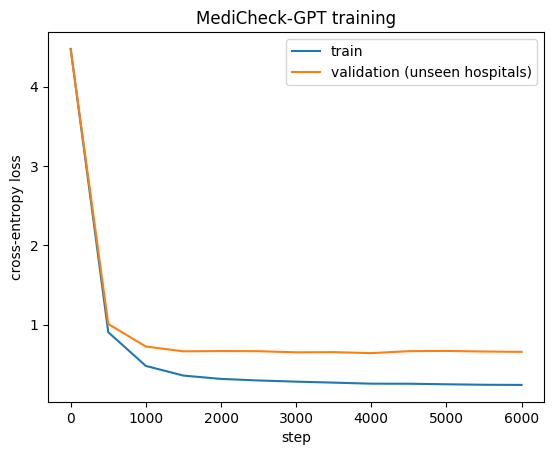

In [37]:
# Loss curve for the slides
import json, matplotlib.pyplot as plt
h = json.load(open('checkpoints/gpt_history.json'))
plt.plot([r['step'] for r in h], [r['train'] for r in h], label='train')
plt.plot([r['step'] for r in h], [r['val'] for r in h], label='validation (unseen hospitals)')
plt.xlabel('step'); plt.ylabel('cross-entropy loss'); plt.legend(); plt.title('MediCheck-GPT training')
plt.savefig('checkpoints/loss_curve.png', dpi=200, bbox_inches='tight'); plt.show()

## 3a. Hyperparameter comparison (Week 7: fine-tuning and hyperparameter tuning)
Same data, same seed, same early stopping. Only the model size and dropout change. About 15 minutes.

In [38]:
# smaller and larger than the base model (base = 4 layers, 4 heads, 128-dim, already trained above)
if not os.path.exists('checkpoints/gpt_large.pth'):
    !python gpt.py --input data/processed --train checkpoints/gpt_small.pth --n_layer 2 --n_head 2 --n_embd 64 --steps 6000
    !python gpt.py --input data/processed --train checkpoints/gpt_large.pth --n_layer 6 --n_head 6 --n_embd 192 --dropout 0.2 --steps 6000

In [39]:
# one table for the slides: which size generalizes best to unseen hospitals?
import math, torch, pandas as pd
from src.model import build, count_params
rows = []
for name in ['gpt_small', 'gpt', 'gpt_large']:
    ck = torch.load(f'checkpoints/{name}.pth', map_location='cpu')
    best = min(ck['history'], key=lambda r: r['val'])            # the checkpoint holds the best evaluation
    rows.append({'model': name, **{k: ck['config'][k] for k in ['n_layer', 'n_head', 'n_embd', 'dropout']},
                 'parameters': count_params(build(ck['kind'], **ck['config'])),
                 'best_step': best['step'], 'best_val_loss': round(best['val'], 4),
                 'val_perplexity': round(math.exp(best['val']), 3), 'seconds': best['seconds']})
pd.DataFrame(rows)

,model,n_layer,n_head,n_embd,dropout,parameters,best_step,best_val_loss,val_perplexity,seconds
0,gpt_small,2,2,64,0.1,126989,3500,0.7434,2.103,77
1,gpt,4,4,128,0.1,846285,4000,0.6403,1.897,331
2,gpt_large,6,6,192,0.2,2747789,1500,0.6341,1.885,302


## 3b. Kacper's recommendation: an LLM teacher writes plain-English descriptions (v2)
Run 1 showed the teacher invents numbers (14%) and, worse, attaches real numbers to the wrong label. v2 gives the LLM each fact as a full phrase and one example, rejects sentences with invented or mislabeled numbers, and gives each rejected record one retry. About 25–30 minutes.

In [40]:
import os
if not os.path.exists('data/described_v2/test.txt'):       # the teacher is the slow step: never run it twice
    !python gpt.py --input data/processed --teacher data/described_v2 --limit 5000
print(open('data/described_v2/teacher_report.json').read())
!head -c 1200 data/described_v2/train.txt

{
 "train": {
  "records": 5000,
  "kept": 3328,
  "rejected": {
   "invented_number": 928,
   "wrong_label": 2201,
   "format": 0,
   "too_long": 0
  }
 },
 "val": {
  "records": 987,
  "kept": 594,
  "rejected": {
   "invented_number": 205,
   "wrong_label": 459,
   "format": 0,
   "too_long": 0
  }
 },
 "test": {
  "records": 762,
  "kept": 518,
  "rejected": {
   "invented_number": 159,
   "wrong_label": 293,
   "format": 0,
   "too_long": 0
  }
 }
}

Corewell Health Zeeland Hospital in Zeeland, MI billed DRG 871 (SEPTICEMIA OR SEVERE SEPSIS WITHOUT MV >96 HOURS WITH MCC) for 53 discharges: covered charges $28663, total payment $12681, Medicare payment $10761. || Corewell Health Zeeland Hospital treated 53 Medicare patients with septicemia or severe sepsis without mechanical ventilation for more than 96 hours, averaging a bill of $28,663 but receiving $12,681 in total payments, with Medicare covering 85% of those payments.
Promedica Charles And Virginia Hickman Hospital in Adrian, 

## 3c. Student v2: pre-train, then fine-tune (Lecture 6–7)
Run 1 trained from scratch on random windows; it learned the teacher's style but ignored the record. v2 starts from the record model (`gpt.pth`, which already knows records) and fine-tunes on whole examples with the loss on the explanation only. Validation loss here is explanation-only, so it is not comparable with run 1's.

In [41]:
if not os.path.exists('checkpoints/explain_v2.pth'):
    !python gpt.py --input data/described_v2 --train checkpoints/explain_v2.pth --init_from checkpoints/gpt.pth --steps 4000 --eval_every 250 --patience 4

In [42]:
# pass the record as a Python argument: records contain '$', which the shell would eat
import subprocess
rec = open('data/processed/test.txt').read().split('\n')[1]
print('record :', rec)
print(subprocess.run(['python', 'gpt.py', '--eval', 'checkpoints/explain_v2.pth', '--prompt', rec, '--n', '3', '--temperature', '0.5'],
                     capture_output=True, text=True).stdout)

record : Munson Healthcare Grayling Hospital in Grayling, MI billed DRG 177 (RESPIRATORY INFECTIONS AND INFLAMMATIONS WITH MCC) for 27 discharges: covered charges $37016, total payment $15466, Medicare payment $14681.
device: cuda
Munson Healthcare Otsego Medicare patients an Gaylord, MI, treated 10 Medicare patients with red blood cell disorders, averaging a bill of $35,052 but receiving $17,794 in total payments, with Medicare covering 86% of the cost. 

Munson Healthcare Otsego Memorial Hospital treated 15 Medicare patients with inflammatory and knee replacements, averaging a bill of $47,539 but receiving $10,516 in total payments, with Medicare covering 83% of those payments. 

Munson Healthcare Otsego Memorial Hospital treated 14 Medicare patients with respiratory infections and inflammations, averaging a bill of $28,632 per patient, but received $14,470 in total payments, with Medicare covering 72% of the cost. 




## 3d. Student v3: placeholders (run 3)
Run 2's student read the record's style but wrote numbers from memory: 0% copied. v3 trains on the teacher's sentences with the record's values replaced by placeholders (`{BILL}`, `{TOTAL}`, `{HOSPITAL}`...); the student learns where each one goes and Python puts the real values back. About 15 minutes.

In [43]:
if not os.path.exists('checkpoints/explain_v3.pth'):
    !python gpt.py --input data/described_v2 --train checkpoints/explain_v3.pth --init_from checkpoints/gpt.pth --delex --steps 4000 --eval_every 250 --patience 4
print(subprocess.run(['python', 'gpt.py', '--eval', 'checkpoints/explain_v3.pth', '--prompt', rec, '--n', '3', '--temperature', '0.5'],
                     capture_output=True, text=True).stdout)

device: cuda
context_size 271 -> 578 so one full example fits
started from checkpoints/gpt.pth: 94 weight tensors copied
gpt (explain): 0.89M parameters | vocab 82 | 3,328 train / 594 val examples
Traceback (most recent call last):
  File "/content/medicheck-gpt/gpt.py", line 269, in <module>
    main()
    ~~~~^^
  File "/content/medicheck-gpt/gpt.py", line 177, in main
    train(model, tok, batchers, args, config, args.train,
    ~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
          log_path=args.train.replace('.pth', '_history.json'),  # bigram batches use --context_size
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
          task=task, on_eval=on_eval if args.model == 'gpt' else None)
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/medicheck-gpt/src/train.py", line 47, in train
    l = estimate_loss(model, batchers)
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/_co

## 4. Generate

In [44]:
!python gpt.py --eval checkpoints/gpt.pth --n 3
!python gpt.py --eval checkpoints/gpt.pth --n 2 --prompt "Trinity Health Livonia Hospital in Livonia, MI billed DRG "

device: cuda
Kettering Health Main Campus in Kettering, OH billed DRG 310 (CARDIAC ARRHYTHMIA AND CONDUCTION DISORDERS WITHOUT CC/MCC) for 20 discharges: covered charges $363478, total payment $11525, Medicare payment $18759. 

Corewell Health Dearborn Hospital in Dearborn, MI billed DRG 421 (HIP AND FEMUR PROCEDURES EXCEPT MAJOR JOINT WITH CC) for 33 discharges: covered charges $233233, total payment $20291, Medicare payment $11346. 

Henry Health St Vincent Medical Center in Toledo, OH billed DRG 452 (COMBINED ANTERIOR AND POSTERIOR SPINAL FUSION WITH CC) for 11 discharges: covered charges $17680, total payment $19928, Medicare payment $133937. 

device: cuda
Trinity Health Livonia Hospital in Livonia, MI billed DRG 178 (RESPIRATORY INFECTIONS AND INFLAMMATIONS WITH MCC) for 13 discharges: covered charges $303351, total payment $9759, Medicare payment $7299. 

Trinity Health Livonia Hospital in Livonia, MI billed DRG 281 (ACUTE MYOCARDIAL INFARCTION, DISCHARGED ALIVE WITH CC) for 43 

## 5. Evaluate: perplexity, token accuracy, ROUGE-L (+ BLEU, BERTScore), record validity

In [45]:
# record models (bigram and GPT were evaluated in run 2; skip if the reports exist)
if not os.path.exists('checkpoints/gpt_eval.json'):
    !python gpt.py --input data/processed --evaluate checkpoints/bigram.pth
    !python gpt.py --input data/processed --evaluate checkpoints/gpt.pth --hf_metrics
# explainers: v2 (copy numbers itself) vs v3 (placeholders), same test sentences, same checks
!python gpt.py --input data/described_v2 --evaluate checkpoints/explain_v2.pth --hf_metrics
!python gpt.py --input data/described_v2 --evaluate checkpoints/explain_v3.pth --hf_metrics

device: cuda
Loading weights: 100% 389/389 [00:00<00:00, 4089.70it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
{
 "model": "explain",
 "explanation_perplexity": 1.883,
 "explanation_token_accuracy": 0.857,
 "rougeL": 0.413,
 "bleu": 0.192,
 "bertscore_f1": 0.504,
 "numbers_faithful_to_record": 0.0,
 "passes_teacher_checks": 0.0,
 "names_right_hospital_o

## 6. Flag silent errors
AUC across records (raw surprise; surprise after the name; ratio to the bigram) and the paired test: on the same record, does the planted error raise surprise? 0.5 = chance, below 0.5 = backwards. Runs on CPU too.

In [46]:
!python gpt.py --input data/processed --flag checkpoints/gpt.pth --background checkpoints/bigram.pth
!python gpt.py --input data/processed --flag checkpoints/gpt_large.pth --background checkpoints/bigram.pth

device: cuda
error type            n     auc_raw    auc_cond   auc_ratio  paired_raw       95% CI raw
drg_mismatch        500       0.677       0.521       0.525       0.848   (0.645, 0.703)
wrong_city          500       0.208       0.139       0.147       0.164   (0.183, 0.233)
payments_swapped    500       0.529       0.507       0.514       0.896   (0.495, 0.556)
extra_digit         500       0.542       0.513       0.523       0.994   (0.507, 0.571)

example planted errors:
  drg_mismatch: Munson Healthcare Grayling Hospital in Grayling, MI billed DRG 177 (O.R. PROCEDURES FOR OBESITY WITH CC) for 27 discharges: covered charges $37016, total payment $15466, Medicare payment $14681.
  wrong_city: Munson Healthcare Grayling Hospital in Gaylord, MI billed DRG 177 (RESPIRATORY INFECTIONS AND INFLAMMATIONS WITH MCC) for 27 discharges: covered charges $37016, total payment $15466, Medicare payment $14681.
  payments_swapped: Munson Healthcare Grayling Hospital in Grayling, MI billed DRG 1

## 6b. Demo file for Tuesday: five real test records and five with planted errors, shuffled. Rules catch arithmetic; the model ranks the rest.

In [47]:
import random, sys
sys.path.insert(0, '.')
from src.flag import corrupt, KINDS
from src.data import parse
test = [r for r in open('data/processed/test.txt').read().split('\n') if parse(r)]
train = [r for r in open('data/processed/train.txt').read().split('\n') if parse(r)]
drg = {parse(r)['drg']: parse(r)['desc'] for r in train}
cities = {}
for r in train:
    f = parse(r); cities.setdefault(f['state'], set()).add(f['city'])
cities = {s: sorted(c) for s, c in cities.items()}
rng = random.Random(7)
clean = rng.sample(test, 5)
planted = [corrupt(r, KINDS[i % 4], drg, cities, rng) for i, r in enumerate(rng.sample(test, 5))]
demo = clean + [p for p in planted if p]
rng.shuffle(demo)
open('data/suspicious.txt', 'w').write('\n'.join(demo) + '\n')
open('data/suspicious_answer_key.txt', 'w').write('\n'.join(('PLANTED  ' if r in planted else 'clean    ') + r for r in demo))
!python gpt.py --input data/processed --flag checkpoints/gpt.pth --flag_file data/suspicious.txt   # rules first, then the model
!cat data/suspicious_answer_key.txt

device: cuda
 0.53  RULE: Medicare paid more than the total
       Henry Ford Health Genesys Hospital in Grand Blanc, MI billed DRG 641 (MISCELLANEOUS DISORDERS OF NUTRITION, METABOLISM, FLUIDS AND ELECTROLYTES WITHOUT MCC) for 17 discharges: covered charges $23692, total payment $5169, Medicare payment $7297.
 0.46  RULE: bill is 80x the payment
       University Of Toledo Medical Center in Toledo, OH billed DRG 660 (KIDNEY AND URETER PROCEDURES FOR NON-NEOPLASM WITH CC) for 17 discharges: covered charges $1344260, total payment $16863, Medicare payment $11960.
 0.89  model only
       Genesis Hospital in Zanesville, OH billed DRG 813 (COAGULATION DISORDERS) for 17 discharges: covered charges $33838, total payment $12962, Medicare payment $11906.
 0.75  model only
       University Hospitals - Elyria Medical Center in Westerville, OH billed DRG 683 (RENAL FAILURE WITH CC) for 27 discharges: covered charges $27004, total payment $6404, Medicare payment $5437.
 0.73  model only
       H

## 7. Results are already in Drive (`build-transformer/medicheck/`)

In [48]:
!ls -lh checkpoints/ data/described_v2/

checkpoints/:
total 81M
-rw------- 1 root root  489 Nov 14 22:25 bigram_eval.json
-rw------- 1 root root  300 Nov 14 20:52 bigram_flag.json
-rw------- 1 root root  951 Nov 14 21:20 bigram_history.json
-rw------- 1 root root  27K Nov 14 21:20 bigram.pth
-rw------- 1 root root  175 Nov 14 20:52 explain_eval.json
-rw------- 1 root root 2.3K Nov 14 20:42 explain_history.json
-rw------- 1 root root  26M Nov 14 20:35 explain.pth
-rw------- 1 root root  259 Nov 14 23:15 explain_v2_eval.json
-rw------- 1 root root 3.1K Nov 14 22:24 explain_v2_history.json
-rw------- 1 root root  26M Nov 14 22:20 explain_v2.pth
-rw------- 1 root root  530 Nov 14 22:31 gpt_eval.json
-rw------- 1 root root  635 Nov 14 23:16 gpt_flag.json
-rw------- 1 root root 2.2K Nov 14 21:28 gpt_history.json
-rw------- 1 root root  631 Nov 14 23:16 gpt_large_flag.json
-rw------- 1 root root 1.4K Nov 14 20:20 gpt_large_history.json
-rw------- 1 root root  21M Nov 14 20:13 gpt_large.pth
-rw------- 1 root root 7.8M Nov 14 21:25 g

## Live demo (Tuesday)
`!python gpt.py --eval checkpoints/explain_v3.pth --interactive --temperature 0.5`  (paste a record, get the plain-English sentence)

`!python gpt.py --input data/processed --flag checkpoints/gpt.pth --flag_file data/suspicious.txt`  (rules, then the model's ranking)